# A nested-dissection solver with inverted fronts, in JAX

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Forgotten/jax-lippmann-schwinger/blob/main/notebooks/block_inverse_solver_notebook.ipynb)

The sparsifying preconditioner
([`sparsifying_preconditioner_notebook.ipynb`](sparsifying_preconditioner_notebook.ipynb))
needs a solve with a sparse 9-point matrix $M$ at every GMRES iteration. The `"superlu"`
backend does that solve on the host with SuperLU, through `jax.pure_callback`. On an
accelerator, that means a round trip to the CPU on every iteration.

`jax_ls.nd_solver` is a direct solver written entirely in `jax.numpy`. It factors $M$ by
nested dissection and stores every diagonal block of the factorisation **already
inverted**. A solve then needs no triangular solves at all, only gathers, batched dense
matrix products and scatter-adds:

* The flop count is the same as a triangular solve: an inverted $s\times s$ block has as
  many entries as its $L$ and $U$ together.
* The shape of the work is different. A triangular solve is a chain of dependent steps,
  while a matrix product is fully parallel. Every block at one depth of the tree is
  independent, so each level is a single batched GEMM.
* Several right-hand sides turn mat-vecs into GEMMs, and the cost per right-hand side
  falls.
* Everything is jittable, `vmap`-able and differentiable through
  `jax.lax.custom_linear_solve`, and nothing leaves the device.

As the preconditioner's backend, the factorisation itself runs on the host CPU by default
(`factor_on="cpu"`), because GPUs are slow at the batched complex128 LU; the blocks are
copied to the device once per contrast and every solve stays there. `factor_on="device"`
keeps the factorisation on the device too.

This notebook shows:

1. the structure: the tree, the levels, and what is stored;
2. that the solve is accurate, with pivoting confined to each block;
3. timings against SuperLU as the number of right-hand sides grows;
4. the solver as the `"block_inverse"` backend of the preconditioner;
5. the whole pipeline (factorisation, GMRES, gradients) under `jax.jit`;
6. caching the factorisation across solves at one contrast, and what that saves.

The timings here are from whatever device this notebook runs on. The design targets GPUs:
on a CPU it is roughly at parity with SuperLU, and faster with many right-hand sides.

In [1]:
# On Colab the package is not present, so install it from GitHub.
# Running from a local clone this cell does nothing.
import importlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("google.colab") is not None:
  subprocess.run(
    [
      sys.executable,
      "-m",
      "pip",
      "install",
      "-q",
      "--no-cache-dir",
      "--upgrade",
      "git+https://github.com/Forgotten/jax-lippmann-schwinger.git@main",
    ],
    check=True,
  )
  importlib.invalidate_caches()
  import jax_ls

  importlib.reload(jax_ls)
  if not hasattr(jax_ls, "NDStructure"):
    raise RuntimeError(
      "jax_ls installed but an older build is still loaded. "
      "Use Runtime > Restart session, then run this cell again."
    )

In [2]:
try:
  import context  # noqa: F401
except ImportError:
  pass

import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sps
import scipy.sparse.linalg as spla

import jax
import jax.numpy as jnp

import jax_ls
from jax_ls import nd_solver as nd
from jax_ls import sparsify

jax.config.update("jax_enable_x64", True)
print("JAX backend:", jax.default_backend(), jax.devices())


def gauss(c, width=10.0):
  """A smooth contrast."""
  return lambda x, y: c * jnp.exp(-width * (x**2 + y**2))


def disc(c, radius=0.3):
  """A discontinuous contrast."""
  return lambda x, y: c * (x**2 + y**2 < radius**2) * 1.0


def best_time(fn, repeat=5):
  """Best wall-clock time of `fn()` after one warm-up call."""
  jax.block_until_ready(fn())
  times = []
  for _ in range(repeat):
    start = time.perf_counter()
    jax.block_until_ready(fn())
    times.append(time.perf_counter() - start)
  return min(times)

JAX backend: cpu [CpuDevice(id=0)]


## 1. How nested dissection works

`NDStructure.create(m, n, leaf)` builds the dissection tree of the grid, once per grid.
The two animations below follow that tree on a 15×15 grid: first how it is built, then
how it is eliminated and how a solve runs through it. Each animation shows the grid
next to the tree; the second also shows the matrix of stored blocks.

The next cell draws both animations with `jax_ls.animations` (installed with
`pip install "jax-ls[viz]"`) and saves them as GIFs in `images/`. The markdown
cells after it display them, which works in Jupyter, VS Code and on GitHub. On Colab,
where relative image links do not resolve, the cell displays them itself.

In [3]:
from jax_ls import animations

tree = animations.DissectionTree(15, 15, leaf=3)
animations.animate_dissection(tree, "images/nested_dissection.gif")
animations.animate_elimination(tree, "images/nested_dissection_solve.gif")
print(
  f"{len(tree.nodes)} tree nodes, depth {tree.depth}; animations written to images/"
)

31 tree nodes, depth 4; animations written to images/


### Step 1: the dissection

A box is cut along its longer side by a one-cell-wide *separator*, and each half is cut
again, recursively, until a box has at most `leaf**2` points. Those boxes are the
*leaves*. With a 9-point stencil a one-cell line really does separate the two halves:
no matrix entry couples them except through the separator. Each tree node therefore has

* $S$: its separator, or its whole box for a leaf;
* $B$: the cells adjacent to its box, all of which lie in ancestor separators.

![Nested dissection of a 15x15 grid, depth by depth, beside its tree](images/nested_dissection.gif)

### Step 2: elimination, the two passes of a solve, and what is stored

Elimination runs the tree the other way, from the leaves up. All fronts at one depth
are independent, since their $S$ never touch, so a whole depth is one batched step.
Each front:

1. assembles $F$ from the original entries and its children's Schur complements;
2. inverts $F_{SS}$, with pivoting;
3. sends $F_{BB} - F_{BS} F_{SS}^{-1} F_{SB}$ to its parent, along the highlighted
   tree edge.

A solve repeats that sweep, then goes back down:

* **up the tree:** $b_B \mathrel{-}= \texttt{lower}\, b_S$, then
  $z_S = \texttt{inverse}\, b_S$;
* **down the tree:** $x_S = z_S - \texttt{upper}\, x_B$, using the boundary values
  that a shallower level has just solved.

The right panel numbers the unknowns in elimination order, so each separator is a
contiguous range. Its `inverse` block sits on the diagonal (orange), and its `lower` and
`upper` blocks sit in the rows and columns of its boundary (blue). Together they form
the nested-dissection "arrow" pattern. These dense blocks, stacked per depth, are the
whole factor: no sparse $L$ or $U$ is ever formed.

![Factorisation and solve up and down the tree, with the stored blocks](images/nested_dissection_solve.gif)

### What is stored

$M = LDU$ in this order, but $L$ and $U$ are never formed. Per node, the factorisation
keeps three dense blocks:

| block | shape | meaning |
|---|---|---|
| `inverse` | $s\times s$ | $F_{SS}^{-1}$, with the row pivoting folded in |
| `lower` | $b\times s$ | $F_{BS}F_{SS}^{-1}$, the node's block of $L$ |
| `upper` | $s\times b$ | $F_{SS}^{-1}F_{SB}$, the node's block of $U$ |

It also keeps the index sets that place those blocks: `separator_idx` and `boundary_idx`.
Nodes at the same depth are padded to a common size and stacked, so a level is five
arrays. The solve is then

* up the tree: $b_B \mathrel{-}= \texttt{lower}\, b_S$, $z_S = \texttt{inverse}\, b_S$;
* down the tree: $x_S = z_S - \texttt{upper}\, x_B$.

In [4]:
structure = nd.NDStructure.create(127, 127, leaf=8)
print(f"{'depth':>5} {'k':>5} {'s':>5} {'b':>5} {'stored entries':>15}")
for d, level in enumerate(reversed(structure.levels)):
  k, s, b = level.shape
  print(f"{d:5d} {k:5d} {s:5d} {b:5d} {k * (s * s + 2 * s * b):15.2e}")
print(
  f"total {structure.stored_entries:.2e} complex entries, {16 * structure.stored_entries / 2**20:.0f} MiB in complex128"
)

depth     k     s     b  stored entries
    0     1   127     1        1.64e+04
    1     2    63   127        3.99e+04
    2     4    63   127        7.99e+04
    3     8    31   159        8.66e+04
    4    16    31   128        1.42e+05
    5    32    15    96        9.94e+04
    6    64    15    64        1.37e+05
    7   128     7    48        9.23e+04
    8   256    49    32        1.42e+06
total 2.11e+06 complex entries, 32 MiB in complex128


Storage grows like $N\log N$. The leaf size trades memory, since dense leaf inverses are
large, against the number of levels, each a sequential step of the solve.

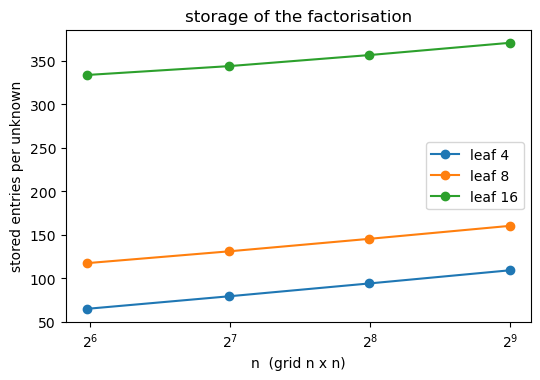

In [5]:
sizes = [63, 127, 255, 511]
plt.figure(figsize=(6, 3.8))
for leaf in (4, 8, 16):
  per_dof = [
    nd.NDStructure.create(n, n, leaf).stored_entries / n**2 for n in sizes
  ]
  plt.plot(sizes, per_dof, "o-", label=f"leaf {leaf}")
plt.xscale("log", base=2)
plt.xlabel("n  (grid n x n)")
plt.ylabel("stored entries per unknown")
plt.legend()
plt.title("storage of the factorisation")
plt.show()

## 2. Accuracy and pivoting

Pivoting is partial and stays inside each $F_{SS}$. A pivot never moves into $B$: that
would make block sizes depend on the data and break the batched layout. The permutation
is folded into `inverse`, so the solve never applies it.

First, a random complex 9-point matrix, against SciPy, in all three modes:

In [6]:
m, n = 40, 52
rng = np.random.default_rng(0)
coef = rng.standard_normal((9, m, n)) + 1j * rng.standard_normal((9, m, n))
coef[4] += 3.0
domain = jax_ls.Domain(1.0, 1.0, n, m)
coef = coef * sparsify._valid_mask(domain)
matrix = sparsify._assemble(domain, coef)

factor = nd.factorize(nd.NDStructure.create(m, n, leaf=8), jnp.asarray(coef))
b = rng.standard_normal((m * n, 4)) + 0j
for mode, op in (("N", matrix), ("T", matrix.T), ("H", matrix.conj().T)):
  x = np.asarray(nd.solve(factor, jnp.asarray(b), mode))
  print(
    f"mode {mode}: relative residual {np.linalg.norm(op @ x - b) / np.linalg.norm(b):.1e}"
  )
print(
  f"element growth {float(factor.growth):.2f}, worst pivot ratio {float(factor.pivot_ratio):.1e}"
)

mode N: relative residual 2.6e-14
mode T: relative residual 3.6e-14


mode H: relative residual 3.6e-14
element growth 1.83, worst pivot ratio 3.2e-02


A matrix with an all-zero diagonal. Elimination without pivoting would divide by zero
at the first step; partial pivoting inside each block handles it.

In [7]:
m = n = 24
coef = 0.1 * (
  rng.standard_normal((9, m, n)) + 1j * rng.standard_normal((9, m, n))
)
coef[4] = 0.0
coef[3] += 1.0
coef[5] += 1.0
domain = jax_ls.Domain(1.0, 1.0, n, m)
coef = coef * sparsify._valid_mask(domain)
matrix = sparsify._assemble(domain, coef)
print("max |diagonal| =", np.abs(matrix.diagonal()).max())

factor = nd.factorize(nd.NDStructure.create(m, n, leaf=4), jnp.asarray(coef))
b = np.ones(m * n, dtype=complex)
x = np.asarray(nd.solve(factor, jnp.asarray(b)))
print(
  f"relative residual {np.linalg.norm(matrix @ x - b) / np.linalg.norm(b):.1e}"
)

max |diagonal| = 0.0


relative residual 4.5e-14


Next, the matrices the solver exists for: the sparsifying matrix
$M = -\mathcal{A} + \omega^2 C D_\nu$ at ten points per wavelength, as the grid grows. The
residual stays near machine precision, and element growth stays small, even at contrast 8
on a disc.

In [8]:
print(
  f"{'n':>5} {'medium':>12} {'residual':>10} {'growth':>8} {'pivot ratio':>12} {'factor (s)':>11}"
)
for n in (63, 127, 255):
  omega = 2 * np.pi * n / 10
  params = jax_ls.init_params(
    1.0, 1.0, n, n, omega, sparsify=True, sparsify_backend="block_inverse"
  )
  stencil, local = params.sparsifier.matrices()
  for name, shape in (("smooth c=8", gauss(8.0)), ("disc c=8", disc(8.0))):
    nu = params.domain.sample(shape)
    matrix = (-stencil + omega**2 * local @ sps.diags(np.asarray(nu))).tocsr()
    factor = sparsify.factor_matrix(params.sparsifier, omega, nu)
    t = best_time(
      lambda: sparsify.factor_matrix(params.sparsifier, omega, nu), repeat=2
    )
    b = np.random.default_rng(1).standard_normal(n * n) + 0j
    x = np.asarray(nd.solve(factor, jnp.asarray(b)))
    res = np.linalg.norm(matrix @ x - b) / np.linalg.norm(b)
    print(
      f"{n:5d} {name:>12} {res:10.1e} {float(factor.growth):8.2f} {float(factor.pivot_ratio):12.1e} {t:11.2f}"
    )

    n       medium   residual   growth  pivot ratio  factor (s)


   63   smooth c=8    6.1e-14     3.92      1.1e-02        0.02
   63     disc c=8    7.5e-14     3.17      3.2e-02        0.02


  127   smooth c=8    6.9e-13     4.52      1.3e-02        0.09


  127     disc c=8    6.0e-14     3.11      3.0e-02        0.08


  255   smooth c=8    2.0e-12     5.75      1.9e-03        0.51


  255     disc c=8    1.8e-11     3.83      1.5e-03        0.50


## 3. Timings against SuperLU

The same matrix ($n = 255$, $\omega$ at ten points per wavelength, disc of contrast 2),
solved for $p$ right-hand sides at once:

* by the jitted block-inverse solve;
* by SuperLU, in the same nested-dissection order, on the host.

On a GPU the block-inverse curve should drop well below what a CPU shows here: its work is
batched GEMMs, and there is no host round trip.

factorisation: block-inverse (jnp) 0.42 s, SuperLU 0.62 s


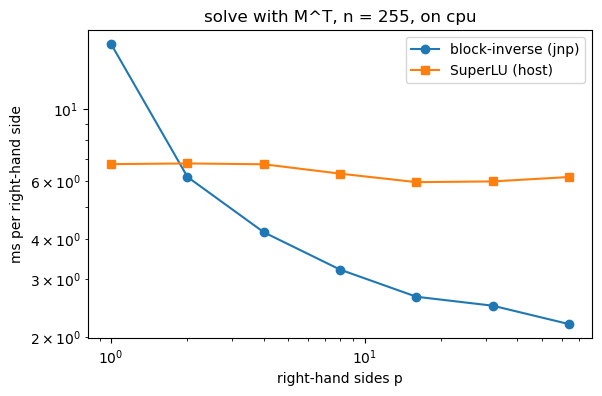

p =   1: block-inverse    15.8 ms   SuperLU     6.8 ms   ratio  0.4x
p =   2: block-inverse    12.4 ms   SuperLU    13.6 ms   ratio  1.1x
p =   4: block-inverse    16.7 ms   SuperLU    27.0 ms   ratio  1.6x
p =   8: block-inverse    25.7 ms   SuperLU    50.6 ms   ratio  2.0x
p =  16: block-inverse    42.4 ms   SuperLU    95.3 ms   ratio  2.2x
p =  32: block-inverse    79.7 ms   SuperLU   191.6 ms   ratio  2.4x
p =  64: block-inverse   140.0 ms   SuperLU   395.2 ms   ratio  2.8x


In [9]:
n = 255
omega = 2 * np.pi * n / 10
params = jax_ls.init_params(
  1.0, 1.0, n, n, omega, sparsify=True, sparsify_backend="block_inverse"
)
stencil, local = params.sparsifier.matrices()
nu = params.domain.sample(disc(2.0))
matrix = (-stencil + omega**2 * local @ sps.diags(np.asarray(nu))).tocsr()

t_factor_jax = best_time(
  lambda: sparsify.factor_matrix(params.sparsifier, omega, nu), repeat=3
)
t0 = time.perf_counter()
superlu = sparsify._PermutedLU(matrix, sparsify.nested_dissection(n, n))
t_factor_superlu = time.perf_counter() - t0
factor = sparsify.factor_matrix(params.sparsifier, omega, nu)
print(
  f"factorisation: block-inverse (jnp) {t_factor_jax:.2f} s, SuperLU {t_factor_superlu:.2f} s"
)

counts = [1, 2, 4, 8, 16, 32, 64]
t_block, t_superlu = [], []
for p in counts:
  b = np.random.default_rng(p).standard_normal((n * n, p)) + 0j
  b_dev = jnp.asarray(b)
  t_block.append(best_time(lambda: nd.solve(factor, b_dev, "T")))
  t_superlu.append(best_time(lambda: superlu.solve(b, trans="T")))

plt.figure(figsize=(6.5, 4))
plt.loglog(
  counts, 1e3 * np.array(t_block) / counts, "o-", label="block-inverse (jnp)"
)
plt.loglog(
  counts, 1e3 * np.array(t_superlu) / counts, "s-", label="SuperLU (host)"
)
plt.xlabel("right-hand sides p")
plt.ylabel("ms per right-hand side")
plt.title(f"solve with M^T, n = {n}, on {jax.default_backend()}")
plt.legend()
plt.show()
for p, a, s in zip(counts, t_block, t_superlu):
  print(
    f"p = {p:3d}: block-inverse {1e3 * a:7.1f} ms   SuperLU {1e3 * s:7.1f} ms   ratio {s / a:4.1f}x"
  )

## 4. As the preconditioner's backend

`backend="block_inverse"` swaps SuperLU for this solver inside the sparsifying
preconditioner. Since both factor $M$ exactly, GMRES behaves identically; only where the
work happens changes.

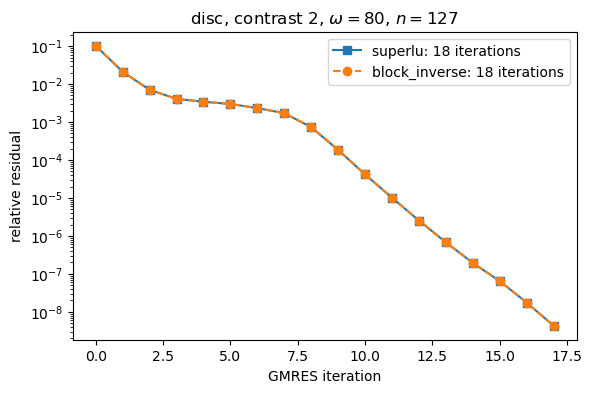

In [10]:
def residual_history(params, nu, budget=200):
  """Relative residual after each GMRES iteration."""
  apply_operator = jax.jit(lambda v: jax_ls.apply_lipp_schwin(params, nu, v))
  apply_precond = jax.jit(jax_ls.preconditioner_for(params, nu))
  b = np.random.default_rng(0).standard_normal(params.n_dof) + 0j
  history = []
  spla.gmres(
    spla.LinearOperator(
      (params.n_dof,) * 2,
      matvec=lambda y: np.array(apply_operator(apply_precond(jnp.asarray(y)))),
      dtype=complex,
    ),
    b,
    rtol=1e-8,
    restart=budget,
    maxiter=1,
    callback=history.append,
    callback_type="pr_norm",
  )
  return np.asarray(history)


n, omega = 127, 80.0
base = jax_ls.init_params(1.0, 1.0, n, n, omega)
by_backend = {
  backend: jax_ls.with_sparsifying_preconditioner(base, backend=backend)
  for backend in ("superlu", "block_inverse")
}
nu = base.domain.sample(disc(2.0))

plt.figure(figsize=(6.5, 4))
for (backend, params), marker in zip(by_backend.items(), ("s-", "o--")):
  history = residual_history(params, nu)
  plt.semilogy(history, marker, label=f"{backend}: {len(history)} iterations")
plt.xlabel("GMRES iteration")
plt.ylabel("relative residual")
plt.title(r"disc, contrast 2, $\omega = 80$, $n = 127$")
plt.legend()
plt.show()

Wall-clock time of the near-field map: 32 sources, one solve each, all at one contrast. The
SuperLU backend factors once on the host and sends every GMRES iteration's 32 vectors
there and back. The block-inverse backend factors in JAX and keeps everything in one
compiled program.

In [11]:
near_plain = jax_ls.init_params_near_field(1.0, 1.0, 127, 127, 1.0, 32, 80.0)
nu = near_plain.ls_params.domain.sample(gauss(2.0))
timings = {}
for backend in ("superlu", "block_inverse"):
  near = near_plain.replace(
    ls_params=jax_ls.with_sparsifying_preconditioner(
      near_plain.ls_params, backend=backend
    )
  )

  def run(near=near):
    sparsify.clear_factorizations()  # charge the SuperLU factorisation every time
    return jax_ls.near_field_map(near, nu)

  timings[backend] = best_time(run, repeat=2)
  print(f"{backend:>14}: {timings[backend]:.2f} s")

       superlu: 6.38 s


 block_inverse: 6.03 s


## 5. Everything under `jax.jit`

`factorize` and `solve` are jitted, and the structure and the factor are ordinary pytrees.
A preconditioned solve is therefore one compiled program: the factorisation from the
traced contrast, GMRES, and the preconditioner inside it. `vmap` over sources batches the
mat-vecs into GEMMs, and `jax.grad` goes through it all. Derivatives with respect to the
contrast come from `custom_linear_solve` differentiating $M^T$, not from differentiating
the factorisation.

In [12]:
params = by_backend["block_inverse"]
nu = params.domain.sample(gauss(2.0))
sources = jnp.asarray(
  np.random.default_rng(3).standard_normal((params.n_dof, 8)) + 0j
)


@jax.jit
def energy(nu):
  """Total |sigma|^2 over eight sources: one factorisation, eight GMRES solves."""
  sigma = jax.vmap(
    lambda f: jax_ls.ls_solver(params, nu, f), in_axes=1, out_axes=1
  )(sources)
  return jnp.sum(jnp.abs(sigma) ** 2)


value, gradient = jax.value_and_grad(energy)(nu)
print(
  f"energy {float(value):.4e}, |gradient| {float(jnp.linalg.norm(gradient)):.4e}"
)

# Check the gradient against a finite difference along a smooth direction.
direction = params.domain.sample(gauss(1.0, width=30.0))
step = 1e-6
fd = (energy(nu + step * direction) - energy(nu - step * direction)) / (
  2 * step
)
print(
  f"directional derivative: autodiff {float(jnp.vdot(gradient, direction).real):.6e}, finite difference {float(fd):.6e}"
)
print(
  "host factorisations:",
  sparsify.factorization_stats().get("factorizations", 0),
)

energy 4.1808e+05, |gradient| 2.8297e+04


directional derivative: autodiff 1.259642e+05, finite difference 1.259642e+05
host factorisations: 0


## 6. Caching the factorisation

The block-inverse preconditioner factors $M(\nu)$ from the contrast it is given. Left to
itself, every batched solve factors again. Many solves share one contrast, though:

* the primal and tangent solves of a JVP;
* the forward and adjoint solves of a gradient;
* every application of $J$ and $J^H$ in a Gauss–Newton step, of which CG on the normal
  equations makes two per iteration.

`jax_ls.preconditioner_factors(params, nu)` factors once and returns a
`PreconditionerFactors` pytree. The solvers accept it as `factors=`. For a real contrast
the adjoint operator uses the same factorisation, so only one is computed. The library
threads it through on its own:

* `linearize` stores it in the `Linearization`, so `jvp` and `vjp` reuse it.
* The JVP and VJP rules of the near-field map and the loss's `custom_vjp` keep it as a
  residual.

`linearize(..., cache_factors=False)` turns the cache off, purely to measure what it
saves. The SuperLU backend needs none of this, since it caches on the host by hashing the
contrast.

`sparsify.factorization_stats()["device_factorizations"]` counts how many factorisations
the compiled code actually ran, through a `jax.debug.callback`:

In [13]:
def device_factorisations(fn):
  # Run `fn` once compiled, and count the factorisations it executes.
  jax.block_until_ready(fn())
  sparsify.clear_factorizations()
  jax.block_until_ready(fn())
  return sparsify.factorization_stats().get("device_factorizations", 0)


near = jax_ls.init_params_near_field(1.0, 1.0, 63, 63, 1.0, 8, 40.0)
near = near.replace(
  ls_params=jax_ls.with_sparsifying_preconditioner(
    near.ls_params, backend="block_inverse"
  )
)
nu = near.ls_params.domain.sample(gauss(2.0))
t = near.ls_params.domain.sample(gauss(1.0, width=30.0))
w = jnp.ones(near.n_sources * near.n_receivers, dtype=complex)
data = jax_ls.near_field_map(near, 1.1 * nu)
inner = jax_ls.NormalEquationsConfig(n_iter=10)


def gauss_newton(cache):
  lin = jax_ls.linearize(near, nu, cache_factors=cache)
  return jax_ls.gauss_newton_step(lin, data.reshape(-1) - lin.data, 40.0, inner)


operations = {
  "near_field_map": lambda: jax_ls.near_field_map(near, nu),
  "born_linearization (J t)": lambda: jax_ls.born_linearization(near, nu, t),
  "born_adjoint (J^H w)": lambda: jax_ls.born_adjoint(near, nu, w),
  "loss and gradient": lambda: jax_ls.near_field_l2_loss_and_grad(
    near, data, nu
  ),
  "Gauss-Newton step, 10 CG its, cached": lambda: gauss_newton(True),
  "Gauss-Newton step, 10 CG its, uncached": lambda: gauss_newton(False),
}
for label, fn in operations.items():
  print(f"{label:42s} {device_factorisations(fn):3d} factorisation(s)")

near_field_map                               1 factorisation(s)


born_linearization (J t)                     1 factorisation(s)


born_adjoint (J^H w)                         1 factorisation(s)


loss and gradient                            1 factorisation(s)


Gauss-Newton step, 10 CG its, cached         1 factorisation(s)


Gauss-Newton step, 10 CG its, uncached      24 factorisation(s)


What that saves in time depends on how the factorisation compares with a batched solve.
On a CPU the FFT operator dominates, so the factorisation is a modest share of a solve.
On a GPU the solves get far cheaper and the share grows. The timing below is a full
Gauss–Newton step (linearisation plus 10 CG iterations on the normal equations) with
8 sources, cached and uncached:

In [14]:
print(
  f"{'n':>5} {'cached (s)':>11} {'uncached (s)':>13} {'saved':>7} {'factorisations':>16}"
)
for n in (127, 255):
  omega = 2 * np.pi * n / 10
  near = jax_ls.init_params_near_field(1.0, 1.0, n, n, 1.0, 8, omega)
  near = near.replace(
    ls_params=jax_ls.with_sparsifying_preconditioner(
      near.ls_params, backend="block_inverse"
    )
  )
  nu = near.ls_params.domain.sample(gauss(2.0))
  data = jax_ls.near_field_map(near, 1.1 * nu).reshape(-1)

  def step(cache, near=near, nu=nu, data=data, omega=omega):
    lin = jax_ls.linearize(near, nu, cache_factors=cache)
    return jax_ls.gauss_newton_step(lin, data - lin.data, omega, inner)

  times, counts = {}, {}
  for cache in (True, False):
    counts[cache] = device_factorisations(lambda: step(cache))
    times[cache] = best_time(lambda: step(cache), repeat=2)
  saved = 1 - times[True] / times[False]
  print(
    f"{n:5d} {times[True]:11.2f} {times[False]:13.2f} {100 * saved:6.0f}% {counts[True]:7d} vs {counts[False]:3d}"
  )

    n  cached (s)  uncached (s)   saved   factorisations


  127       35.41         38.94      9%       1 vs  24


  255      135.47        144.67      6%       1 vs  24


## Takeaways

* The factor is three dense blocks per tree node: `inverse`, `lower` and `upper`, stacked
  per level. The solve uses only gathers, batched GEMMs and scatter-adds.
* Partial pivoting inside each block, folded into `inverse`, keeps element growth small
  on every matrix tried, at no cost to the solve.
* With one right-hand side on a CPU, the solver roughly matches SuperLU. With many it is
  faster, because each level is a single BLAS-3 call.
* As the preconditioner's backend it gives exactly the same GMRES iterations, and keeps
  the factorisation, the solve and the gradients inside one jitted JAX program. On a GPU
  the solves need no host round trip; the factorisation makes one per contrast, on the
  host CPU by default (`factor_on="device"` avoids even that).
* The factorisation is cached across every solve at one contrast. A Gauss–Newton step
  factors once instead of once per $J$ or $J^H$ application, with the same results to rounding.
* Not done yet: single precision with iterative refinement.